# Ridge regression with other power-spectrum sizes (D = 10, 30, 70, 90)

Same method as `ridge.ipynb` (D = 50), repeated for every spectrum size:

`log10(P(k))` → standardize → Ridge, with α chosen separately for Ωm and σ8 by 5-fold cross-validation
(train on 4 folds, validate on the 5th, rotate). The final model is trained on all 5 folds and evaluated once on the test set.

- **Data:** `powerspectrum2/D={N}/level{1,2,3}/` for D = 10, 30, 70, 90, and the original `powerspectrum/` for D = 50 (reference).
  All sizes use the same maps, labels, simulation splits and row order.
- **Metrics:** MAE, RMSE and R² per map, and per simulation (the 15 predictions of each simulation averaged first).

In [1]:
from pathlib import Path
import csv

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DIMENSIONS = [10, 30, 50, 70, 90]
LEVELS = [1, 2, 3]
N_FOLDS = 5
ALPHAS = np.logspace(-6, 4, 41)          # same grid as ridge.ipynb
PARAM_NAMES = ["Omega_m", "sigma_8"]
PARAM_TEX = [r"$\Omega_m$", r"$\sigma_8$"]

# D = 50 is the original export; the other sizes were recomputed by Aman into powerspectrum2/
DATA_ROOTS = {d: Path("powerspectrum2") / f"D={d}" for d in DIMENSIONS if d != 50}
DATA_ROOTS[50] = Path("powerspectrum")

OUT_DIR = Path("results/ridge_other_dims")
OUT_DIR.mkdir(parents=True, exist_ok=True)

missing = [str(root) for root in DATA_ROOTS.values() if not root.exists()]
if missing:
    raise FileNotFoundError(f"Data folders not found: {missing}. Put powerspectrum2/ next to this notebook.")

## 1. Load the data

In [2]:
def load_leaf(dimension, level, group):
    leaf = DATA_ROOTS[dimension] / f"level{level}" / group
    # log_power_spectra.npy = log10(max(P, 1e-30)); identical to log10(P) for positive spectra
    X = np.load(leaf / "log_power_spectra.npy", allow_pickle=False).astype(np.float64)
    y = np.load(leaf / "labels.npy", allow_pickle=False).astype(np.float64)
    sim_ids = np.load(leaf / "simulation_ids.npy", allow_pickle=False)
    assert len(X) == len(y) == len(sim_ids), f"row mismatch in {leaf}"
    return X, y, sim_ids


data = {}
for d in DIMENSIONS:
    for level in LEVELS:
        folds = [load_leaf(d, level, f"fold{k}") for k in range(1, N_FOLDS + 1)]
        test = load_leaf(d, level, "test")
        data[(d, level)] = (folds, test)

## 2. Sanity checks

- Every D must have the same number of features as its name, and no clipped (non-positive) power values.
- Labels and simulation IDs must be identical across all D, so the comparison is fair.
- No simulation may appear in two splits (fold or test).

In [3]:
for level in LEVELS:
    ref_folds, ref_test = data[(50, level)]
    for d in DIMENSIONS:
        folds, test = data[(d, level)]
        X_all = np.concatenate([f[0] for f in folds] + [test[0]])
        assert X_all.shape[1] == d, f"D={d}: expected {d} features, got {X_all.shape[1]}"
        n_clipped = int(np.sum(X_all <= -29))
        for (_, y, s), (_, y_ref, s_ref) in zip(folds + [test], ref_folds + [ref_test]):
            assert np.array_equal(y, y_ref) and np.array_equal(s, s_ref), f"D={d} level {level}: rows differ from D=50"
        print(f"Level {level}, D={d:>2}: {X_all.shape[0]} maps, {d} features, clipped values: {n_clipped}")

    groups = [set(f[2].tolist()) for f in ref_folds] + [set(ref_test[2].tolist())]
    shared = sum(len(groups[i] & groups[j]) for i in range(len(groups)) for j in range(i + 1, len(groups)))
    print(f"Level {level}: simulations shared between splits: {shared}" + (" (no leakage)" if shared == 0 else "  <-- PROBLEM"))

Level 1, D=10: 1005 maps, 10 features, clipped values: 0
Level 1, D=30: 1005 maps, 30 features, clipped values: 0
Level 1, D=50: 1005 maps, 50 features, clipped values: 0
Level 1, D=70: 1005 maps, 70 features, clipped values: 0
Level 1, D=90: 1005 maps, 90 features, clipped values: 0
Level 1: simulations shared between splits: 0 (no leakage)
Level 2, D=10: 4995 maps, 10 features, clipped values: 0
Level 2, D=30: 4995 maps, 30 features, clipped values: 0
Level 2, D=50: 4995 maps, 50 features, clipped values: 0
Level 2, D=70: 4995 maps, 70 features, clipped values: 0
Level 2, D=90: 4995 maps, 90 features, clipped values: 0
Level 2: simulations shared between splits: 0 (no leakage)
Level 3, D=10: 9000 maps, 10 features, clipped values: 0
Level 3, D=30: 9000 maps, 30 features, clipped values: 0
Level 3, D=50: 9000 maps, 50 features, clipped values: 0
Level 3, D=70: 9000 maps, 70 features, clipped values: 0
Level 3, D=90: 9000 maps, 90 features, clipped values: 0
Level 3: simulations shared

## 3. Cross-validation: choose α for each D, level and parameter

In [4]:
def make_model(alpha):
    # features are already log10(P); the scaler is fitted on training folds only
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha))


def cross_validate(folds, alphas):
    # RMSE and MAE arrays of shape (n_folds, n_alphas, 2 parameters)
    rmse = np.zeros((len(folds), len(alphas), 2))
    mae = np.zeros_like(rmse)
    for k in range(len(folds)):
        X_val, y_val, _ = folds[k]
        X_tr = np.concatenate([f[0] for i, f in enumerate(folds) if i != k])
        y_tr = np.concatenate([f[1] for i, f in enumerate(folds) if i != k])
        for a, alpha in enumerate(alphas):
            pred = make_model(alpha).fit(X_tr, y_tr).predict(X_val)
            rmse[k, a] = np.sqrt(((pred - y_val) ** 2).mean(axis=0))
            mae[k, a] = np.abs(pred - y_val).mean(axis=0)
    return rmse, mae


cv = {}
for level in LEVELS:
    for d in DIMENSIONS:
        rmse, mae = cross_validate(data[(d, level)][0], ALPHAS)
        best_idx = rmse.mean(axis=0).argmin(axis=0)
        cv[(d, level)] = dict(rmse=rmse, mae=mae, best_idx=best_idx, best_alpha=ALPHAS[best_idx])
        text = "   ".join(
            f"{name}: alpha={ALPHAS[i]:.3g}, CV RMSE={rmse[:, i, t].mean():.4f}±{rmse[:, i, t].std():.4f}"
            for t, (name, i) in enumerate(zip(PARAM_NAMES, best_idx)))
        print(f"Level {level}, D={d:>2}   {text}")
        if any(i in (0, len(ALPHAS) - 1) for i in best_idx):
            print("    WARNING: best alpha is at the edge of the grid, widen ALPHAS.")

Level 1, D=10   Omega_m: alpha=100, CV RMSE=0.0959±0.0170   sigma_8: alpha=10, CV RMSE=0.0978±0.0175


Level 1, D=30   Omega_m: alpha=100, CV RMSE=0.0955±0.0161   sigma_8: alpha=56.2, CV RMSE=0.0978±0.0170


Level 1, D=50   Omega_m: alpha=100, CV RMSE=0.0953±0.0157   sigma_8: alpha=100, CV RMSE=0.0977±0.0170


Level 1, D=70   Omega_m: alpha=178, CV RMSE=0.0952±0.0160   sigma_8: alpha=178, CV RMSE=0.0978±0.0171


Level 1, D=90   Omega_m: alpha=178, CV RMSE=0.0953±0.0158   sigma_8: alpha=178, CV RMSE=0.0978±0.0170


Level 2, D=10   Omega_m: alpha=31.6, CV RMSE=0.0906±0.0056   sigma_8: alpha=10, CV RMSE=0.0956±0.0044


... (5 outputs left out)

Level 3, D=30   Omega_m: alpha=100, CV RMSE=0.0920±0.0035   sigma_8: alpha=178, CV RMSE=0.0989±0.0043


Level 3, D=50   Omega_m: alpha=178, CV RMSE=0.0919±0.0034   sigma_8: alpha=316, CV RMSE=0.0989±0.0043


Level 3, D=70   Omega_m: alpha=178, CV RMSE=0.0919±0.0035   sigma_8: alpha=316, CV RMSE=0.0989±0.0044


Level 3, D=90   Omega_m: alpha=316, CV RMSE=0.0919±0.0035   sigma_8: alpha=562, CV RMSE=0.0989±0.0043


## 4. Final models and test evaluation

In [5]:
def simulation_average(pred, y, sim_ids):
    ids = np.unique(sim_ids)
    pred_sim = np.array([pred[sim_ids == i].mean(axis=0) for i in ids])
    y_sim = np.array([y[sim_ids == i][0] for i in ids])
    return pred_sim, y_sim


rows = []
for level in LEVELS:
    for d in DIMENSIONS:
        folds, (X_test, y_test, sim_test) = data[(d, level)]
        X_tr = np.concatenate([f[0] for f in folds])
        y_tr = np.concatenate([f[1] for f in folds])

        model = make_model(cv[(d, level)]["best_alpha"]).fit(X_tr, y_tr)
        pred = model.predict(X_test)
        np.save(OUT_DIR / f"test_predictions_D{d}_level{level}.npy", pred)
        pred_sim, y_sim = simulation_average(pred, y_test, sim_test)
        mean_pred = np.tile(y_tr.mean(axis=0), (len(y_test), 1))

        for t, name in enumerate(PARAM_NAMES):
            rows.append({
                "level": level, "D": d, "parameter": name, "n_train": len(X_tr),
                "alpha": cv[(d, level)]["best_alpha"][t],
                "MAE": mean_absolute_error(y_test[:, t], pred[:, t]),
                "RMSE": np.sqrt(mean_squared_error(y_test[:, t], pred[:, t])),
                "R2": r2_score(y_test[:, t], pred[:, t]),
                "sim_MAE": mean_absolute_error(y_sim[:, t], pred_sim[:, t]),
                "sim_RMSE": np.sqrt(mean_squared_error(y_sim[:, t], pred_sim[:, t])),
                "sim_R2": r2_score(y_sim[:, t], pred_sim[:, t]),
                "baseline_RMSE": np.sqrt(mean_squared_error(y_test[:, t], mean_pred[:, t])),
            })

with open(OUT_DIR / "ridge_other_dims_results.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)

for name in PARAM_NAMES:
    print(f"\n=== {name} ===")
    print(f"{'level':>5} {'D':>3} {'alpha':>9}   {'MAE':>7} {'RMSE':>7} {'R2':>7}   {'simMAE':>7} {'simRMSE':>7} {'simR2':>7}   {'base RMSE':>9}")
    for r in rows:
        if r["parameter"] == name:
            print(f"{r['level']:>5} {r['D']:>3} {r['alpha']:>9.3g}   {r['MAE']:>7.4f} {r['RMSE']:>7.4f} {r['R2']:>7.3f}   "
                  f"{r['sim_MAE']:>7.4f} {r['sim_RMSE']:>7.4f} {r['sim_R2']:>7.3f}   {r['baseline_RMSE']:>9.4f}")
print(f"\nSaved to {OUT_DIR / 'ridge_other_dims_results.csv'}")


=== Omega_m ===


level   D     alpha       MAE    RMSE      R2    simMAE simRMSE   simR2   base RMSE
    1  10       100    0.1143  0.1287   0.264    0.1135  0.1252   0.302      0.1500
    1  30       100    0.1126  0.1268   0.285    0.1118  0.1233   0.324      0.1500
    1  50       100    0.1124  0.1266   0.287    0.1116  0.1229   0.328      0.1500
    1  70       178    0.1125  0.1267   0.286    0.1118  0.1231   0.326      0.1500
    1  90       178    0.1124  0.1268   0.285    0.1116  0.1230   0.327      0.1500
    2  10      31.6    0.0745  0.0880   0.398    0.0689  0.0801   0.502      0.1138
    2  30      56.2    0.0737  0.0872   0.410    0.0678  0.0790   0.515      0.1138
    2  50       100    0.0735  0.0869   0.414    0.0678  0.0788   0.518      0.1138
    2  70       178    0.0734  0.0868   0.415    0.0678  0.0787   0.519      0.1138
    2  90       178    0.0734  0.0868   0.415    0.0677  0.0787   0.519      0.1138
    3  10      31.6    0.0758  0.0935   0.377    0.0689  0.0841   0.497    

## 5. Best D per level

In [6]:
for level in LEVELS:
    for metric in ["RMSE", "sim_RMSE"]:
        parts = []
        for name in PARAM_NAMES:
            sel = [r for r in rows if r["level"] == level and r["parameter"] == name]
            best = min(sel, key=lambda r: r[metric])
            ref = next(r for r in sel if r["D"] == 50)
            parts.append(f"{name}: D={best['D']} ({best[metric]:.4f} vs D=50 {ref[metric]:.4f})")
        print(f"Level {level}, lowest {metric:8s} -> " + "   ".join(parts))

Level 1, lowest RMSE     -> Omega_m: D=50 (0.1266 vs D=50 0.1266)   sigma_8: D=30 (0.1072 vs D=50 0.1072)
Level 1, lowest sim_RMSE -> Omega_m: D=50 (0.1229 vs D=50 0.1229)   sigma_8: D=30 (0.0995 vs D=50 0.0996)
Level 2, lowest RMSE     -> Omega_m: D=70 (0.0868 vs D=50 0.0869)   sigma_8: D=30 (0.0934 vs D=50 0.0934)
Level 2, lowest sim_RMSE -> Omega_m: D=90 (0.0787 vs D=50 0.0788)   sigma_8: D=70 (0.0863 vs D=50 0.0864)
Level 3, lowest RMSE     -> Omega_m: D=50 (0.0925 vs D=50 0.0925)   sigma_8: D=50 (0.1000 vs D=50 0.1000)
Level 3, lowest sim_RMSE -> Omega_m: D=70 (0.0827 vs D=50 0.0827)   sigma_8: D=70 (0.0940 vs D=50 0.0940)


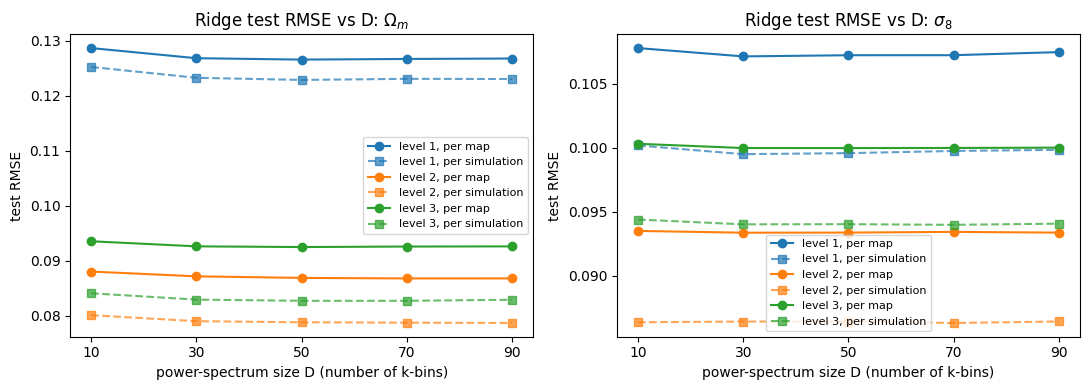

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for t, ax in enumerate(axes):
    for level in LEVELS:
        sel = sorted((r for r in rows if r["level"] == level and r["parameter"] == PARAM_NAMES[t]), key=lambda r: r["D"])
        line, = ax.plot([r["D"] for r in sel], [r["RMSE"] for r in sel], "o-", label=f"level {level}, per map")
        ax.plot([r["D"] for r in sel], [r["sim_RMSE"] for r in sel], "s--", color=line.get_color(),
                alpha=0.7, label=f"level {level}, per simulation")
    ax.set_xticks(DIMENSIONS)
    ax.set_xlabel("power-spectrum size D (number of k-bins)")
    ax.set_ylabel("test RMSE")
    ax.set_title(f"Ridge test RMSE vs D: {PARAM_TEX[t]}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "rmse_vs_D.png", dpi=150)
plt.show()

## Outputs

All saved in `results/ridge_other_dims/`:
- `ridge_other_dims_results.csv`: chosen α, MAE, RMSE, R² (per map and per simulation) and baseline RMSE for every level, D and parameter
- `test_predictions_D{D}_level{L}.npy`: test-set predictions, columns (Ωm, σ8)
- `rmse_vs_D.png`: test RMSE against D

The D = 50 rows reproduce the numbers in `ridge.ipynb`, which confirms the pipeline is unchanged.